# Part 2: Bayesian Probability on IMDb Reviews

For this part we want to know how likely a review is to be positive if it contains a certain word. We only calculate P(Positive | keyword), not the negative version.

P(Positive | kw) = P(kw | Positive) × P(Positive) / P(kw)

- Prior, P(Positive): the share of all reviews that are positive
- Likelihood, P(kw | Positive): the share of positive reviews that contain the word
- Marginal, P(kw): the share of all reviews that contain the word
- Posterior, P(Positive | kw): the share of reviews with the word that are positive

The calculations only use basic Python (csv and re). Matplotlib is only used to draw the chart.

In [9]:
from google.colab import files
uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]
print("Loaded file:", DATA_PATH)

Saving IMDB Dataset.csv to IMDB Dataset (1).csv
Loaded file: IMDB Dataset (1).csv


In [10]:
%%writefile bayes_imdb.py
# Part 2: Bayes' theorem on the IMDb reviews, basic Python only (csv and re).
# We work out P(Positive | keyword) = P(kw | Positive) * P(Positive) / P(kw)
import csv
import re

DATA_PATH = "data/IMDB_Dataset.csv"

POSITIVE_KEYWORDS = ["superb", "outstanding", "wonderful", "excellent"]
NEGATIVE_KEYWORDS = ["worst", "waste", "awful", "terrible"]

WORD_RE = re.compile(r"[a-z']+")


def load_reviews(path=DATA_PATH):
    # returns a list of (set of words, sentiment), one entry per review
    # a set means a word is only counted once per review
    reviews = []
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            text = row["review"].lower().replace("<br />", " ")
            words = set(WORD_RE.findall(text))
            reviews.append((words, row["sentiment"].strip().lower()))
    return reviews


def count_stats(reviews, keywords):
    # counts how many reviews contain each keyword, and how many of those are positive
    n_total = len(reviews)
    n_pos = sum(1 for _, sentiment in reviews if sentiment == "positive")
    kw_total = {k: 0 for k in keywords}
    kw_pos = {k: 0 for k in keywords}
    for words, sentiment in reviews:
        for k in keywords:
            if k in words:
                kw_total[k] += 1
                if sentiment == "positive":
                    kw_pos[k] += 1
    return n_total, n_pos, kw_total, kw_pos


def bayes_posterior(prior, likelihood, marginal):
    # Bayes' theorem, this is the only place the formula is written
    if marginal == 0:
        raise ValueError("this keyword is not in any review, P(keyword) = 0")
    return likelihood * prior / marginal


def analyse(reviews, keywords):
    n_total, n_pos, kw_total, kw_pos = count_stats(reviews, keywords)
    prior = n_pos / n_total                       # P(Positive)
    results = []
    for k in keywords:
        likelihood = kw_pos[k] / n_pos            # P(kw | Positive)
        marginal = kw_total[k] / n_total          # P(kw)
        posterior = bayes_posterior(prior, likelihood, marginal)
        direct = kw_pos[k] / kw_total[k]          # same answer worked out from counts, to check
        results.append({"keyword": k, "count_pos": kw_pos[k], "count_all": kw_total[k],
                        "prior": prior, "likelihood": likelihood, "marginal": marginal,
                        "posterior": posterior, "direct": direct})
    return results


def print_table(title, results):
    print(f"\n{title}")
    print(f"{'keyword':<13}{'P(Pos)':>8}{'P(kw|Pos)':>11}{'P(kw)':>9}{'P(Pos|kw)':>11}{'check':>8}{'#reviews':>10}")
    print("-" * 70)
    for r in results:
        print(f"{r['keyword']:<13}{r['prior']:>8.4f}{r['likelihood']:>11.4f}"
              f"{r['marginal']:>9.4f}{r['posterior']:>11.4f}{r['direct']:>8.4f}{r['count_all']:>10}")


def markdown_table(results):
    lines = ["| Keyword | Prior P(Positive) | Likelihood P(kw\\|Positive) | Marginal P(kw) | Posterior P(Positive\\|kw) |",
             "|---|---|---|---|---|"]
    for r in results:
        lines.append(f"| {r['keyword']} | {r['prior']:.4f} | {r['likelihood']:.4f} | "
                     f"{r['marginal']:.4f} | {r['posterior']:.4f} |")
    return "\n".join(lines)


def main():
    reviews = load_reviews()
    print("Loaded", len(reviews), "reviews")
    print_table("Positive keywords", analyse(reviews, POSITIVE_KEYWORDS))
    print_table("Negative keywords", analyse(reviews, NEGATIVE_KEYWORDS))


if __name__ == "__main__":
    main()

Overwriting bayes_imdb.py


In [11]:
import bayes_imdb as b

reviews = b.load_reviews(DATA_PATH)
n_total = len(reviews)
n_pos = sum(1 for _, s in reviews if s == "positive")
print("Total reviews:", n_total)
print("Positive reviews:", n_pos)
print("Negative reviews:", n_total - n_pos)
print("Prior P(Positive):", n_pos / n_total)

Total reviews: 50000
Positive reviews: 25000
Negative reviews: 25000
Prior P(Positive): 0.5


## Choosing the keywords

Positive: superb, outstanding, wonderful, excellent

Negative: worst, waste, awful, terrible

We did not just pick words we liked. We tried a bigger list of words first and looked at how many reviews each one appears in and how strongly it points to positive or negative. We kept the words that appear in plenty of reviews (at least 743 each, so the numbers are not based on a handful of reviews) and that clearly point one way.

In [12]:
candidates = ["superb", "outstanding", "wonderful", "excellent", "fantastic", "amazing",
              "perfect", "brilliant", "boring", "dull", "horrible", "terrible",
              "awful", "worst", "waste"]
pool = sorted(b.analyse(reviews, candidates), key=lambda r: -r["posterior"])
chosen = b.POSITIVE_KEYWORDS + b.NEGATIVE_KEYWORDS

print(f"{'word':<13}{'#reviews':>9}{'P(Pos|kw)':>11}   chosen?")
print("-" * 44)
for r in pool:
    mark = "YES" if r["keyword"] in chosen else ""
    print(f"{r['keyword']:<13}{r['count_all']:>9}{r['posterior']:>11.3f}   {mark}")

word          #reviews  P(Pos|kw)   chosen?
--------------------------------------------
superb            1199      0.856   YES
outstanding        743      0.832   YES
wonderful         2777      0.812   YES
excellent         3549      0.807   YES
fantastic         1350      0.799   
amazing           2156      0.778   
perfect           2658      0.766   
brilliant         2084      0.761   
boring            3049      0.194   
dull              1392      0.184   
horrible          2098      0.155   
terrible          2696      0.141   YES
awful             2875      0.098   YES
worst             4428      0.092   YES
waste             2533      0.069   YES


Words we left out and why:

- brilliant (0.761) and perfect (0.766) were the weakest of the positive words. Both show up in mixed reviews, for example "a brilliant idea but badly acted".
- boring (0.194) and dull (0.184) were the weakest of the negative words. People write things like "never boring" in good reviews.
- fantastic and amazing were fine but a bit weaker than the four we kept.

## The four probabilities

We call `analyse` once for the positive words and once for the negative words. The `check` column works out the posterior a second way, straight from the counts (positive reviews with the word divided by all reviews with the word). It should match the Bayes answer.

In [13]:
pos = b.analyse(reviews, b.POSITIVE_KEYWORDS)
neg = b.analyse(reviews, b.NEGATIVE_KEYWORDS)

b.print_table("Positive keywords", pos)
b.print_table("Negative keywords", neg)

for r in pos + neg:
    assert abs(r["posterior"] - r["direct"]) < 1e-12
print("\nBayes results match the direct count for every keyword")


Positive keywords
keyword        P(Pos)  P(kw|Pos)    P(kw)  P(Pos|kw)   check  #reviews
----------------------------------------------------------------------
superb         0.5000     0.0410   0.0240     0.8557  0.8557      1199
outstanding    0.5000     0.0247   0.0149     0.8318  0.8318       743
wonderful      0.5000     0.0902   0.0555     0.8120  0.8120      2777
excellent      0.5000     0.1146   0.0710     0.8073  0.8073      3549

Negative keywords
keyword        P(Pos)  P(kw|Pos)    P(kw)  P(Pos|kw)   check  #reviews
----------------------------------------------------------------------
worst          0.5000     0.0164   0.0886     0.0924  0.0924      4428
waste          0.5000     0.0070   0.0507     0.0687  0.0687      2533
awful          0.5000     0.0112   0.0575     0.0977  0.0977      2875
terrible       0.5000     0.0152   0.0539     0.1413  0.1413      2696

Bayes results match the direct count for every keyword


In [14]:
from IPython.display import Markdown, display
display(Markdown(b.markdown_table(pos + neg)))

| Keyword | Prior P(Positive) | Likelihood P(kw\|Positive) | Marginal P(kw) | Posterior P(Positive\|kw) |
|---|---|---|---|---|
| superb | 0.5000 | 0.0410 | 0.0240 | 0.8557 |
| outstanding | 0.5000 | 0.0247 | 0.0149 | 0.8318 |
| wonderful | 0.5000 | 0.0902 | 0.0555 | 0.8120 |
| excellent | 0.5000 | 0.1146 | 0.0710 | 0.8073 |
| worst | 0.5000 | 0.0164 | 0.0886 | 0.0924 |
| waste | 0.5000 | 0.0070 | 0.0507 | 0.0687 |
| awful | 0.5000 | 0.0112 | 0.0575 | 0.0977 |
| terrible | 0.5000 | 0.0152 | 0.0539 | 0.1413 |

## Worked example for one word

Here is "superb" worked out from the raw counts.

In [15]:
r = pos[0]
print("Keyword:", r["keyword"])
print(f"Reviews with the word: {r['count_all']} out of {n_total}")
print(f"Positive reviews with the word: {r['count_pos']} out of {n_pos}")
print()
print(f"Prior      = {n_pos}/{n_total} = {r['prior']:.4f}")
print(f"Likelihood = {r['count_pos']}/{n_pos} = {r['likelihood']:.4f}")
print(f"Marginal   = {r['count_all']}/{n_total} = {r['marginal']:.4f}")
print(f"Posterior  = {r['likelihood']:.4f} x {r['prior']:.4f} / {r['marginal']:.4f} = {r['posterior']:.4f}")

Keyword: superb
Reviews with the word: 1199 out of 50000
Positive reviews with the word: 1026 out of 25000

Prior      = 25000/50000 = 0.5000
Likelihood = 1026/25000 = 0.0410
Marginal   = 1199/50000 = 0.0240
Posterior  = 0.0410 x 0.5000 / 0.0240 = 0.8557


## Chart

The dashed line is the prior (0.5). Bars above it mean the word makes a positive review more likely, bars below it mean less likely.

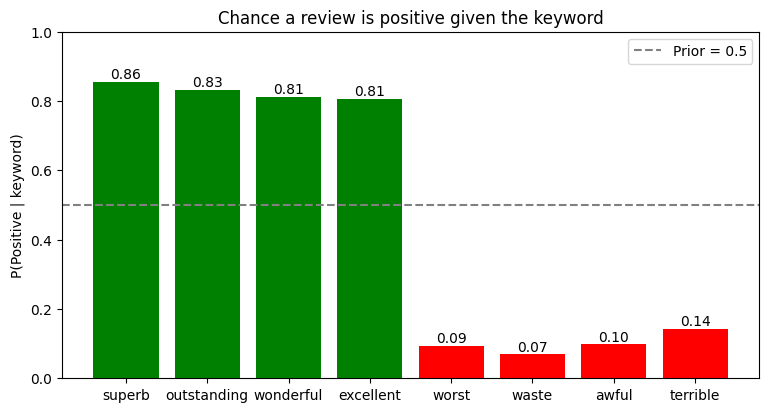

In [16]:
import matplotlib.pyplot as plt

rows = pos + neg
names = [r["keyword"] for r in rows]
posts = [r["posterior"] for r in rows]
colors = ["green"] * len(pos) + ["red"] * len(neg)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(names, posts, color=colors)
plt.axhline(0.5, linestyle="--", color="gray", label="Prior = 0.5")
for bar, p in zip(bars, posts):
    plt.text(bar.get_x() + bar.get_width() / 2, p + 0.01, f"{p:.2f}", ha="center")
plt.ylabel("P(Positive | keyword)")
plt.title("Chance a review is positive given the keyword")
plt.ylim(0, 1)
plt.legend()
plt.savefig("posterior_chart.png", dpi=150)
plt.show()

## What the results show

- The prior is 0.5 because the dataset has 25,000 positive and 25,000 negative reviews.
- All four positive words are well above 0.5. "superb" is the highest at 0.856.
- All four negative words are well below 0.5. "waste" is the lowest at 0.069, so about 93% of the reviews that contain it are negative. A low number is what we expect for a negative word because we are calculating P(Positive | keyword).
- "excellent" has the highest likelihood (0.1146) but "superb" has the higher posterior. The posterior also depends on how often the word shows up in negative reviews, which is why we divide by P(kw).

## Limits

- It looks at one word at a time, so it misses things like "not terrible" or sarcasm.
- One word only shifts the probability, it does not decide the sentiment.
- The prior of 0.5 only holds because this dataset is balanced.